# Consumption patterns

Daily, weekly and yearly cycles of French electricity consumption, and
the effect of public holidays.

In [1]:
import holidays
import matplotlib.pyplot as plt
import pandas as pd

from load_forecast.db import read_sql

cons = read_sql("SELECT ts, consumption_mw FROM consumption WHERE consumption_mw IS NOT NULL")
cons["ts"] = pd.to_datetime(cons["ts"], utc=True).dt.tz_convert("Europe/Paris")
cons["time_of_day"] = cons["ts"].dt.hour + cons["ts"].dt.minute / 60
cons["weekday"] = cons["ts"].dt.dayofweek
cons["is_weekend"] = cons["weekday"] >= 5
cons.head()

,ts,consumption_mw,time_of_day,weekday,is_weekend
0,2012-01-01 23:00:00+01:00,56577,23.0,6,True
1,2012-01-01 23:30:00+01:00,55634,23.5,6,True
2,2012-01-02 00:00:00+01:00,55164,0.0,0,False
3,2012-01-03 04:00:00+01:00,55743,4.0,1,False
4,2012-01-03 04:30:00+01:00,55656,4.5,1,False


## Days

In [2]:
weekdays = cons[~cons["is_weekend"]].groupby("time_of_day")["consumption_mw"].mean()
weekends = cons[cons["is_weekend"]].groupby("time_of_day")["consumption_mw"].mean()
weekdays.head()

time_of_day
0.0    53738.547860
0.5    51988.242739
1.0    49443.978994
1.5    49079.642635
2.0    48538.782676
Name: consumption_mw, dtype: float64

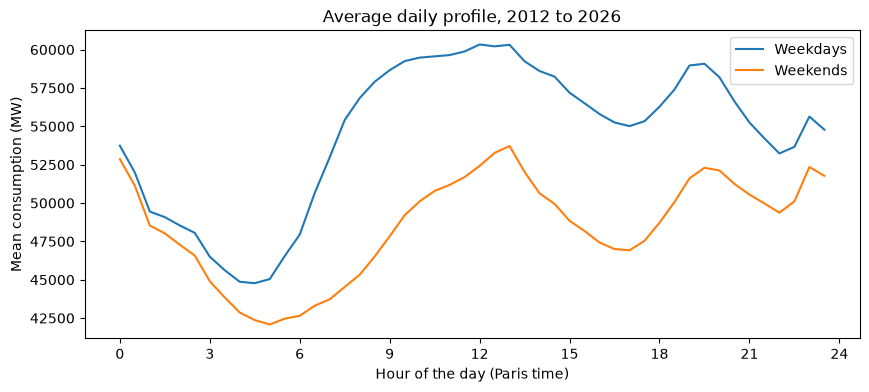

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(weekdays.index, weekdays.values, label="Weekdays")
ax.plot(weekends.index, weekends.values, label="Weekends")
ax.set_xlabel("Hour of the day (Paris time)")
ax.set_ylabel("Mean consumption (MW)")
ax.set_xticks(range(0, 25, 3))
ax.set_title("Average daily profile, 2012 to 2026")
ax.legend()
plt.show()

## Daily profile

Weekdays and weekends follow the same overall shape: consumption is
lowest around 5:00 and peaks around 13:00 and 20:00.

Weekends are about 10000 MW lower than weekdays, and the morning rise
starts later, around 8:00 instead of 5:00.

In [4]:
by_weekday = cons.groupby("weekday")["consumption_mw"].mean()
by_weekday.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_weekday.round(0)

Mon    53562.0
Tue    54901.0
Wed    55032.0
Thu    54877.0
Fri    54304.0
Sat    49593.0
Sun    47404.0
Name: consumption_mw, dtype: float64

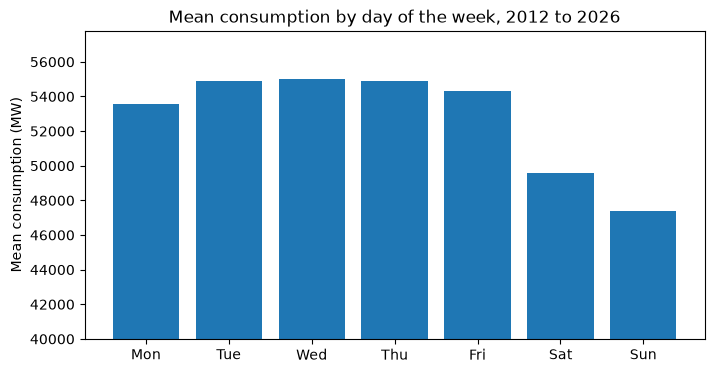

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_weekday.index, by_weekday.values)
ax.set_ylabel("Mean consumption (MW)")
ax.set_ylim(40_000, None)
ax.set_title("Mean consumption by day of the week, 2012 to 2026")
plt.show()

## Months

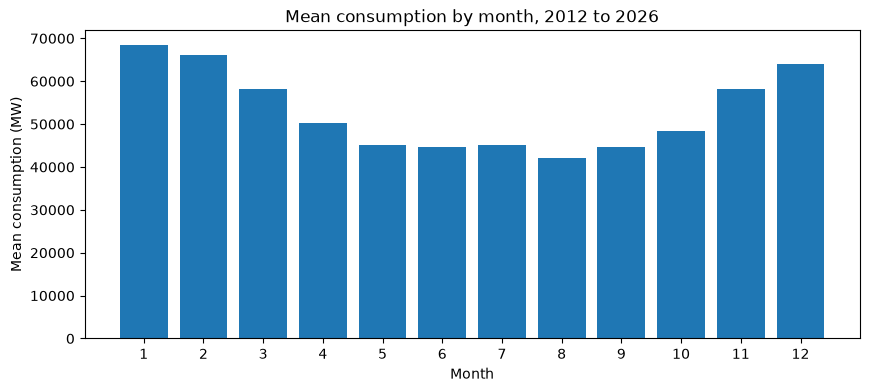

In [6]:
by_month = cons.groupby(cons["ts"].dt.month)["consumption_mw"].mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(by_month.index, by_month.values)
ax.set_xticks(range(1, 13))
ax.set_xlabel("Month")
ax.set_ylabel("Mean consumption (MW)")
ax.set_title("Mean consumption by month, 2012 to 2026")
plt.show()

## Yearly cycle

Consumption follows a U-shaped yearly cycle: it is highest in January
and lowest in August, about 20,000 MW lower. It rises again through
autumn into winter, driven by electric heating.

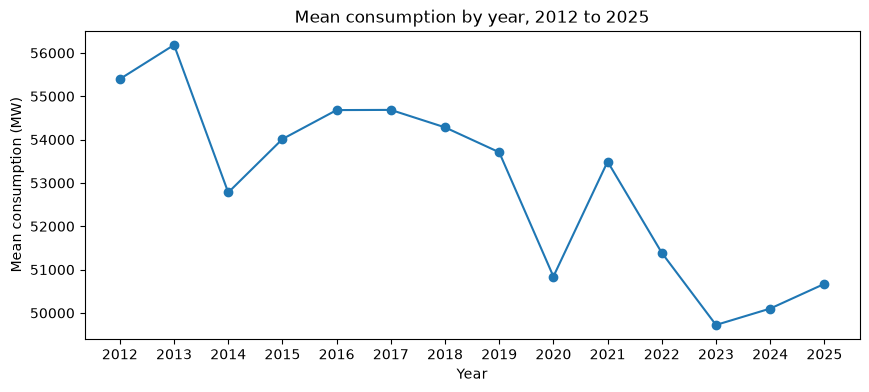

In [7]:
complete_years = cons[cons["ts"].dt.year < 2026]
by_year = complete_years.groupby(complete_years["ts"].dt.year)["consumption_mw"].mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(by_year.index, by_year.values, marker="o")
ax.set_xticks(by_year.index)
ax.set_xlabel("Year")
ax.set_ylabel("Mean consumption (MW)")
ax.set_title("Mean consumption by year, 2012 to 2025")
plt.show()

## Long-term trend

Mean consumption was highest in 2013, possibly because of a cold winter. It then
decreased from 2016 onwards, probably because of energy efficiency and
milder winters. 2020 stands out as the lowest year, likely due to the
COVID-19 lockdowns. The consumption starts to rise again from 2023.


## Holidays

In [8]:
fr_holidays = holidays.France(years=range(2012, 2027))
cons["date"] = cons["ts"].dt.date
cons["is_holiday"] = cons["date"].isin(list(fr_holidays))
sorted(fr_holidays.items())[:12]

[(datetime.date(2012, 1, 1), "Jour de l'an"),
 (datetime.date(2012, 4, 9), 'Lundi de Pâques'),
 (datetime.date(2012, 5, 1), 'Fête du Travail'),
 (datetime.date(2012, 5, 8), 'Fête de la Victoire'),
 (datetime.date(2012, 5, 17), 'Ascension'),
 (datetime.date(2012, 5, 28), 'Lundi de Pentecôte'),
 (datetime.date(2012, 7, 14), 'Fête nationale'),
 (datetime.date(2012, 8, 15), 'Assomption'),
 (datetime.date(2012, 11, 1), 'Toussaint'),
 (datetime.date(2012, 11, 11), 'Armistice'),
 (datetime.date(2012, 12, 25), 'Noël'),
 (datetime.date(2013, 1, 1), "Jour de l'an")]

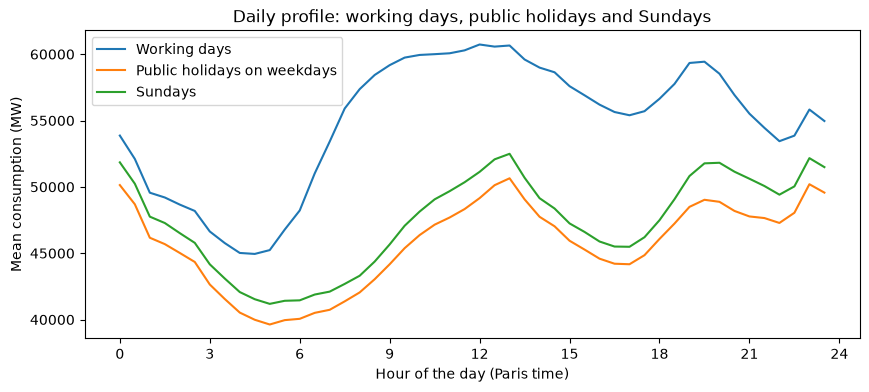

In [9]:
working_days = cons[~cons["is_weekend"] & ~cons["is_holiday"]]
weekday_holidays = cons[~cons["is_weekend"] & cons["is_holiday"]]
sundays = cons[cons["weekday"] == 6]

fig, ax = plt.subplots(figsize=(10, 4))
for subset, label in [
    (working_days, "Working days"),
    (weekday_holidays, "Public holidays on weekdays"),
    (sundays, "Sundays"),
]:
    profile = subset.groupby("time_of_day")["consumption_mw"].mean()
    ax.plot(profile.index, profile.values, label=label)
ax.set_xlabel("Hour of the day (Paris time)")
ax.set_ylabel("Mean consumption (MW)")
ax.set_xticks(range(0, 25, 3))
ax.set_title("Daily profile: working days, public holidays and Sundays")
ax.legend()
plt.show()

Consumption on holidays and Sundays are nearly the same, with a slightly higher consumption on Sundays.